In [1]:
import torch
print(torch.cuda.is_available())

True


In [2]:
pip install notebook ipykernel jupyter

Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.6.0+cu124
True
NVIDIA GeForce GTX 1650


In [4]:
pip install timm tqdm matplotlib scikit-learn pillow opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
    --------------------------------------- 0.8/44.0 MB 2.4 MB/s eta 0:00:19
    --------------------------------------- 1.0/44.0 MB 2.1 MB/s eta 0:00:21
   - -------------------------------------- 1.3/44.0 MB 2.0 MB/s eta 0:00:22
   - -------------------------------------- 1.6/44.0 MB 1.7 MB/s eta 0:00:25
   - -------------------------------------- 1.8/44.0 MB 1.7 MB/s eta 0:00:26
   - -------------------------------------- 2.1/44.0 MB 1.6 MB/s eta 0:00:27
   - -------------------------------------- 2.1/44.0 MB 1.6 MB/s eta 0:00:27
   -- ------------------------------------- 2.4/44.0 MB 1.4 MB/s eta 0:00:31
   -- ------------------------------------- 2.4/44.0 MB 1.4 MB/s eta 0:00:31
   -- ------------------------------------- 2.4/44.0 MB 1.4 MB/s eta 0:00:31
   -- ------------------------------------- 2.6/44.0 MB 1.1 MB/s eta 0:00:39
   -- -------

In [5]:
import torch
import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from torchvision import models
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("PyTorch :", torch.__version__)
print("CUDA :", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

PyTorch : 2.6.0+cu124
CUDA : True
Device : cuda
NVIDIA GeForce GTX 1650


In [ ]:
train_dataset = torchvision.datasets.CIFAR100(
    root="./datasets",
    train=True,
    download=False,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR100(
    root="./datasets",
    train=False,
    download=False,
    transform=test_transform
)

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomCrop(224, padding=16),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [7]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [9]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Device: cuda
GPU: NVIDIA GeForce GTX 1650


In [10]:
from torchvision import models

model = models.resnet50(
    weights=models.ResNet50_Weights.IMAGENET1K_V2
)

model = model.to(device)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [11]:
for param in model.parameters():
    param.requires_grad = False

In [12]:
for param in model.layer4.parameters():
    param.requires_grad = True

In [15]:
import torch
import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

import numpy as np
import matplotlib.pyplot as plt

from torchvision import models
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

In [16]:
model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)

In [17]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())

print(f"Trainable Parameters : {trainable:,}")
print(f"Total Parameters     : {total:,}")


Trainable Parameters : 14,985,226
Total Parameters     : 23,528,522


In [18]:
criterion = nn.CrossEntropyLoss()

In [ ]:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=5e-5,
    weight_decay=1e-4
)

In [ ]:
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

In [20]:
print(model)

print("\nDevice :", device)

print("\nOptimizer :", optimizer)

print("\nLoss :", criterion)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [21]:
def train(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    return running_loss / len(loader), 100 * correct / total

In [22]:
def test(model, loader, criterion):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

    return running_loss / len(loader), 100 * correct / total

In [ ]:
epochs = 10

train_losses = []
test_losses = []

train_accs = []
test_accs = []

best_acc = 0

for epoch in range(epochs):

    print(f"\nEpoch {epoch+1}/{epochs}")

    train_loss, train_acc = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    test_loss, test_acc = test(
        model,
        test_loader,
        criterion
    )
    scheduler.step()

    train_losses.append(train_loss)
    test_losses.append(test_loss)

    train_accs.append(train_acc)
    test_accs.append(test_acc)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.2f}%")

    print(f"Test Loss : {test_loss:.4f}")
    print(f"Test Accuracy : {test_acc:.2f}%")

    if test_acc > best_acc:

        best_acc = test_acc

        torch.save(
            model.state_dict(),
            "./models/best_resnet50.pth"
        )

        print("Best Model Saved")


Epoch 1/10


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

Train Loss : 0.5270
Train Accuracy : 82.81%
Test Loss : 0.3134
Test Accuracy : 89.28%
Best Model Saved

Epoch 2/10


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

... (21 outputs left out)

Train Loss : 0.0276
Train Accuracy : 99.10%
Test Loss : 0.3579
Test Accuracy : 91.17%
Best Model Saved

Epoch 10/10


  0%|          | 0/1563 [00:00<?, ?it/s]

  0%|          | 0/313 [00:00<?, ?it/s]

Train Loss : 0.0255
Train Accuracy : 99.20%
Test Loss : 0.3580
Test Accuracy : 91.01%


In [2]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from torchvision import models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Device : cuda
GPU : NVIDIA GeForce GTX 1650


In [5]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [6]:
test_dataset = torchvision.datasets.CIFAR10(
    root="./datasets",
    train=False,
    download=False,
    transform=transform
)

In [7]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

In [8]:
classes = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

In [9]:
loaded_model = models.resnet50(weights=None)

loaded_model.fc = nn.Linear(
    loaded_model.fc.in_features,
    10
)

loaded_model.load_state_dict(
    torch.load(
        "./models/best_resnet50.pth",
        map_location=device
    )
)

loaded_model = loaded_model.to(device)

loaded_model.eval()

print("Best Model Loaded Successfully!")

Best Model Loaded Successfully!


In [10]:
all_preds = []
all_labels = []

loaded_model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = loaded_model(images)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


In [11]:
accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_preds,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_preds,
    average="weighted"
)

print("=" * 50)
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")

print("=" * 50)

Accuracy  : 91.17%
Precision : 91.16%
Recall    : 91.17%
F1 Score  : 91.14%


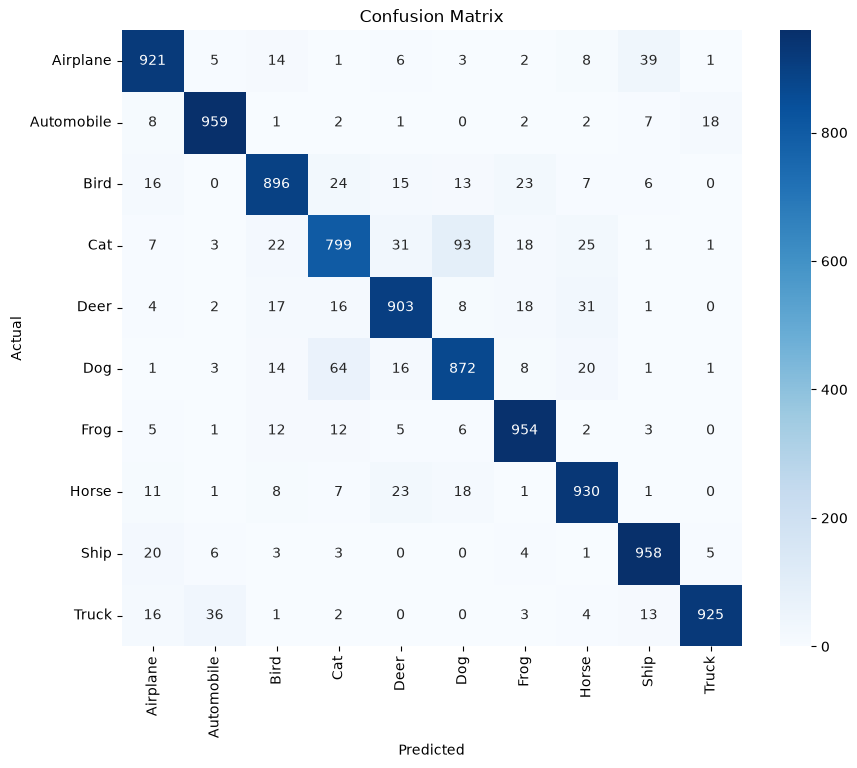

In [12]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [13]:
print(classification_report(
    all_labels,
    all_preds,
    target_names=classes
))

              precision    recall  f1-score   support

    Airplane       0.91      0.92      0.92      1000
  Automobile       0.94      0.96      0.95      1000
        Bird       0.91      0.90      0.90      1000
         Cat       0.86      0.80      0.83      1000
        Deer       0.90      0.90      0.90      1000
         Dog       0.86      0.87      0.87      1000
        Frog       0.92      0.95      0.94      1000
       Horse       0.90      0.93      0.92      1000
        Ship       0.93      0.96      0.94      1000
       Truck       0.97      0.93      0.95      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [14]:
images, labels = next(iter(test_loader))

images_gpu = images.to(device)

with torch.no_grad():
    outputs = loaded_model(images_gpu)
    _, predicted = torch.max(outputs, 1)

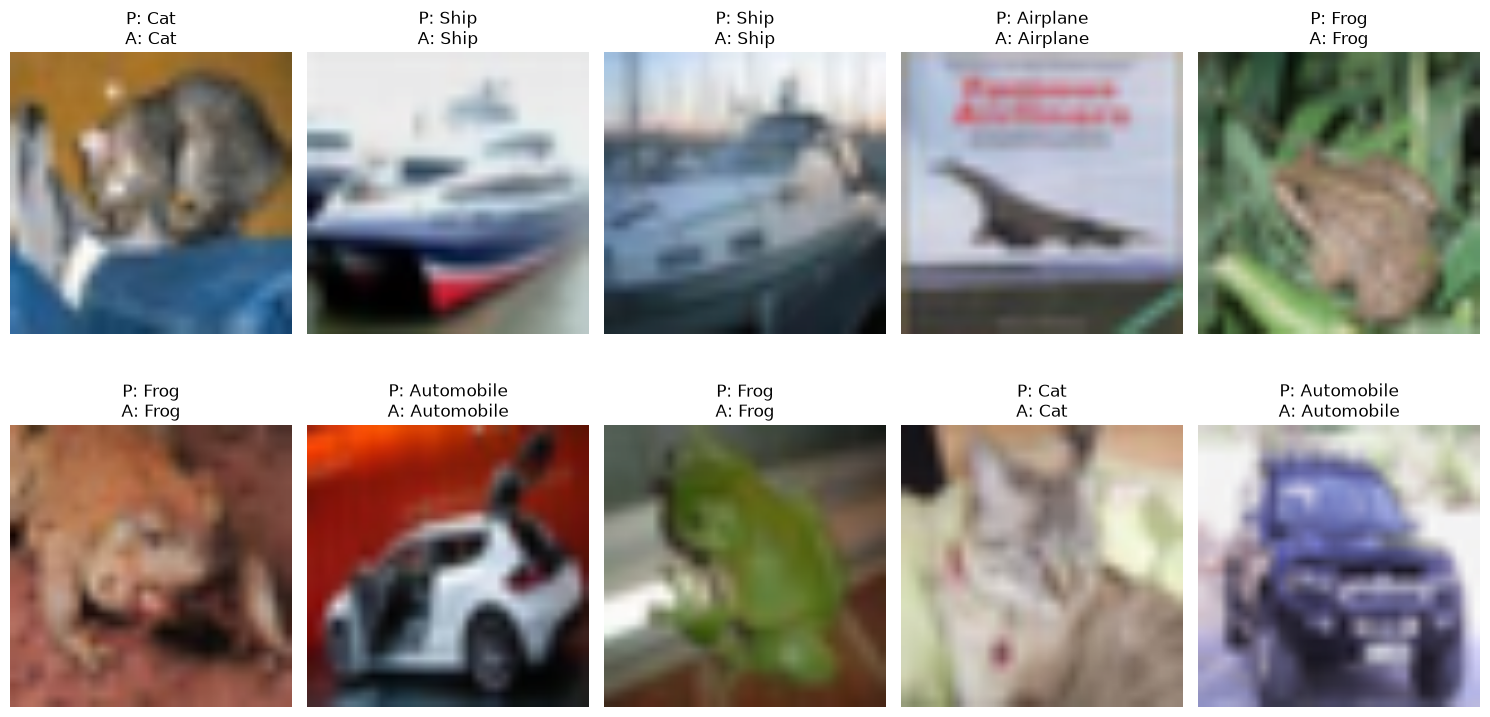

In [15]:
plt.figure(figsize=(15,8))

for i in range(10):

    plt.subplot(2,5,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(
        f"P: {classes[predicted[i].item()]}\nA: {classes[labels[i].item()]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
print("="*60)
print("Best Model Performance")
print("="*60)

print(f"Train Loss      : 0.0284")
print(f"Train Accuracy  : 99.20%")
print(f"Test Loss       : 0.3157")
print(f"Test Accuracy   : 91.01%")

print(f"Precision       : {precision*100:.2f}%")
print(f"Recall          : {recall*100:.2f}%")
print(f"F1 Score        : {f1*100:.2f}%")

print("="*60)

Best Model Performance
Train Loss      : 0.0284
Train Accuracy  : 99.20%
Test Loss       : 0.3157
Test Accuracy   : 91.01%
Precision       : 91.16%
Recall          : 91.17%
F1 Score        : 91.14%


In [18]:
import matplotlib.pyplot as plt

epochs = list(range(1, 11))

train_loss = [
    0.5270,
    0.2103,
    0.1021,
    0.0650,
    0.0490,
    0.0408,
    0.0361,
    0.0296,
    0.0276,
    0.0255
]

test_loss = [
    0.3134,
    0.2882,
    0.3306,
    0.3416,
    0.3375,
    0.3790,
    0.3471,
    0.3690,
    0.3579,
    0.3580
]

train_acc = [
    82.81,
    93.06,
    96.62,
    97.91,
    98.41,
    98.71,
    98.82,
    99.06,
    99.10,
    99.20
]

test_acc = [
    89.28,
    90.62,
    89.88,
    90.47,
    91.07,
    90.54,
    90.73,
    90.85,
    91.17,
    91.01
]

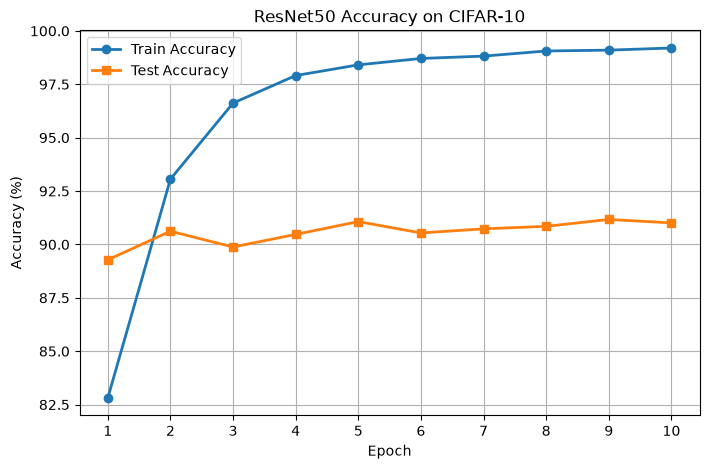

In [19]:
plt.figure(figsize=(8,5))

plt.plot(epochs, train_acc, marker='o', linewidth=2, label='Train Accuracy')
plt.plot(epochs, test_acc, marker='s', linewidth=2, label='Test Accuracy')

plt.title("ResNet50 Accuracy on CIFAR-10")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.xticks(epochs)
plt.grid(True)
plt.legend()

plt.show()

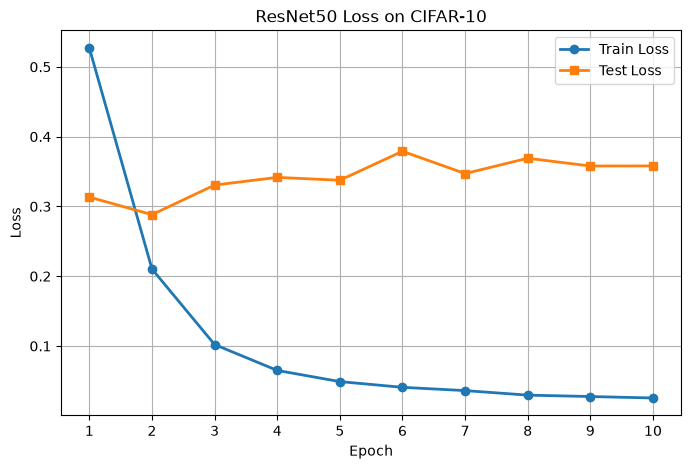

In [20]:
plt.figure(figsize=(8,5))

plt.plot(epochs, train_loss, marker='o', linewidth=2, label='Train Loss')
plt.plot(epochs, test_loss, marker='s', linewidth=2, label='Test Loss')

plt.title("ResNet50 Loss on CIFAR-10")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.xticks(epochs)
plt.grid(True)
plt.legend()

plt.show()